# LeapQuant 教程 (2/5): int8 量化入门 —— 舍入误差从哪来、怎么会累积

上一本讲清了被量化的对象 (GDN 状态账本)。这一本讲**量化本身**:

1. fp32 → int8 是什么操作, 误差多大;
2. 把状态每步量化一次, 误差为什么在递推里**滚雪球**;
3. 稀少量化 (每 16 步一次) 已经能好 6 倍 —— 但还不够, 引出教程 3 的 LeapQuant 量化器。

In [1]:
import sys, math
import torch

sys.path.insert(0, "/workspace/y00924007/vllm-ascend")  # 开发树 (分支 leapquant-triton-m3)

try:
    import torch_npu  # noqa: F401 — 注册 npu 后端
    DEV = torch.device("npu") if torch.npu.is_available() else torch.device("cpu")
except Exception:
    DEV = torch.device("cpu")

import warnings, logging
warnings.filterwarnings("ignore")
logging.getLogger("vllm").setLevel(logging.ERROR)

torch.manual_seed(20261110)
print(f"torch = {torch.__version__}   device = {DEV}")

torch = 2.10.0+cpu   device = npu


/usr/local/python3.11.10/lib/python3.11/site-packages/torch_npu/_init/core/optional_features.py:20: UserWarning: On the interactive interface, the value of TASK_QUEUE_ENABLE is set to 0 by default. Do not set it to 1 to avoid unexpected errors.
  warnings.warn(


In [2]:
H, K, V = 8, 128, 128        # Qwen3.5-0.8B 单卡 GDN 头几何 (128×128)
B, WINDOW, R = 4, 16, 4      # 批 / 窗口 / 补偿秩 (论文 8-bit 最优)
SCALE = K ** -0.5

def gdn_inputs(B, H, T, K=K, V=V, dev=DEV):
    q = torch.nn.functional.normalize(torch.randn(B, H, T, K, device=dev), dim=-1)
    k = torch.nn.functional.normalize(torch.randn(B, H, T, K, device=dev), dim=-1)
    v = torch.randn(B, H, T, V, device=dev)
    g = -torch.rand(B, H, T, device=dev) * 0.1       # log 域衰减率 ∈ [-0.1, 0)
    beta = torch.rand(B, H, T, device=dev).sigmoid() # delta 门控
    return q, k, v, g, beta

def gdn_step(h, q, k, v, g, beta):
    """一步递推 (逐项拆解见教程 1): 衰减 → delta 修正 → 外积更新。"""
    h = h * g.exp()[..., None, None]
    v_adj = (v - torch.einsum("bhvk,bhk->bhv", h, k)) * beta[..., None]
    return h + torch.einsum("bhv,bhk->bhvk", v_adj, k)

def gdn_out(h, q):
    return torch.einsum("bhvk,bhk->bhv", h, q) * SCALE

def trajectory(inputs, window=None, boundary_fn=None, every_step_fn=None):
    """跑 T 步; 可选在窗口边界 / 每步对状态做一次变换 (量化实验的注入点)。"""
    q, k, v, g, beta = inputs
    B, H, T = q.shape[0], q.shape[1], q.shape[2]
    h = torch.zeros(B, H, V, K, device=q.device)
    outs = []
    for t in range(T):
        h = gdn_step(h, q[:, :, t], k[:, :, t], v[:, :, t], g[:, :, t], beta[:, :, t])
        if every_step_fn is not None:
            h = every_step_fn(h)
        elif boundary_fn is not None and (t + 1) % window == 0:
            h = boundary_fn(h)
        outs.append(gdn_out(h, q[:, :, t]))
    return h, torch.stack(outs, dim=2)

print("GDN 模拟器就绪 (完整拆解见教程 1)")

GDN 模拟器就绪 (完整拆解见教程 1)


## 1. 对称 int8 量化: 一个"只有 256 个刻度"的世界

fp32 有 32 位, 动态范围极大; int8 只有 **256 个整数格点** $[-127, 127]$。
对称量化就是给一组数选一个**刻度尺** $s$, 把它们四舍五入到格点上:

$$s = \frac{\max|x|}{127}, \qquad q = \mathrm{round}\!\left(\frac{x}{s}\right) \in [-127,127], \qquad \hat{x} = q \cdot s$$

存的是 $q$ (1 字节), 用的时候 $\hat{x}$ 还原。误差 = **round 的舍入误差**, 每个 $x$ 最多偏差 $s/2$。
`per-tensor` 指整个矩阵共用一把刻度尺 —— 这是最朴素 (也最不准) 的做法。

In [3]:
import torch

X = torch.tensor([[0.10, -0.30, 0.52],
                  [-0.47, 0.05, 0.28],
                  [0.33, -0.21, 0.41]])        # 手算例子 (无随机)

s = X.abs().max() / 127                          # 刻度尺: 最大绝对值 / 127
q = torch.round(X / s)                           # 落到 int8 格点
x_hat = q * s                                    # 反量化还原
print(f"刻度尺 s = {s:.5f}   (一格 = {s:.5f}, 舍入最多偏差 s/2 = {s/2:.5f})\n")
print("原始 X:\n", X.numpy())
print("整数量化 q:\n", q.numpy().astype(int))
print("还原 x̂:\n", x_hat.numpy().round(4))
err = (x_hat - X).abs().max()
print(f"\n逐元素最大误差 = {err:.5f}, 相对误差 ‖x̂−X‖/‖X‖ = {((x_hat-X).norm()/X.norm()):.3%}")

刻度尺 s = 0.00409   (一格 = 0.00409, 舍入最多偏差 s/2 = 0.00205)

原始 X:
 [[ 0.1  -0.3   0.52]
 [-0.47  0.05  0.28]
 [ 0.33 -0.21  0.41]]
整数量化 q:
 [[  24  -73  127]
 [-115   12   68]
 [  81  -51  100]]
还原 x̂:
 [[ 0.0983 -0.2989  0.52  ]
 [-0.4709  0.0491  0.2784]
 [ 0.3317 -0.2088  0.4094]]

逐元素最大误差 = 0.00173, 相对误差 ‖x̂−X‖/‖X‖ = 0.357%


## 2. 误差多大? 随机 128×128 矩阵测一次

约定全书 的误差度量: **相对 Frobenius 误差** $\;\hat{E} = \|\hat{X}-X\|_F / \|X\|_F$。

In [4]:
g = torch.Generator().manual_seed(7)          # 本地生成器, 不动全局随机流
X = torch.randn(128, 128, generator=g)

s = X.abs().max() / 127
x_hat = torch.round(X / s) * s
print(f"per-tensor int8 round-trip: 相对误差 {((x_hat-X).norm()/X.norm()):.3%}")
print("直觉: 每个元素偏差 ≯ s/2, 而矩阵动态范围 (max/典型值) 越大, 刻度尺越粗, 误差越大")
print("→ 改进思路: 让被量化的东西动态范围小 (教程 3 的'基坐标系'), 或者少量化几次 (下面)")

per-tensor int8 round-trip: 相对误差 0.908%
直觉: 每个元素偏差 ≯ s/2, 而矩阵动态范围 (max/典型值) 越大, 刻度尺越粗, 误差越大
→ 改进思路: 让被量化的东西动态范围小 (教程 3 的'基坐标系'), 或者少量化几次 (下面)


## 3. 关键实验: 状态量化放在**哪个节奏**, 误差天差地别

状态是**递推**的: $S_t$ 由 $S_{t-1}$ 算出。如果每步都把 $S_t$ 量化一次, 舍入误差会**写回账本**,
被下一步继承、再舍入、再放大 —— 滚雪球。

对比三种节奏 (量化器都用最朴素的 per-tensor int8):

| 节奏 | 含义 |
|---|---|
| `never` | 从不量化 (fp32 基线, 误差恒 0) |
| `every step` | 每步量化一次 —— 最直白的"状态 int8 化" |
| `every 16 steps` | 每 16 步量化一次, 中间保持 fp32 —— 窗口机制的雏形 |

In [9]:
from vllm_ascend.quantization.methods.mamba_state.leapquant.state import QMAX

inp1 = gdn_inputs(B, H, WINDOW)               # 先滚一个真实窗口状态
S_win, _ = trajectory(inp1)
s1 = S_win.abs().amax(dim=(-2,-1), keepdim=True) / QMAX
S_q = torch.round(S_win / s1) * s1
print(f"对一个真实边界状态做一次 per-tensor int8: 相对误差 {((S_q-S_win).norm()/S_win.norm()):.3%}\n")

T_LONG = 256
inputs = gdn_inputs(B, H, T_LONG)

def pertensor(h):
    s = h.abs().amax(dim=(-2, -1), keepdim=True).clamp_min(1e-12) / QMAX
    return torch.round(h / s) * s

MODES = {
    "never":        lambda h, at_b: h,
    "every step":   lambda h, at_b: pertensor(h),
    "every 16":     lambda h, at_b: pertensor(h) if at_b else h,
}

def compare(state_fns, window=WINDOW, every=32):
    q, k, v, g, beta = inputs
    T = q.shape[2]
    h_ref = torch.zeros(B, H, V, K, device=DEV)
    hs = {n: torch.zeros_like(h_ref) for n in state_fns}
    log = {n: [] for n in state_fns}
    for t in range(T):
        step = (q[:, :, t], k[:, :, t], v[:, :, t], g[:, :, t], beta[:, :, t])
        h_ref = gdn_step(h_ref, *step)
        at_boundary = (t + 1) % window == 0
        for n, fn in state_fns.items():
            hs[n] = gdn_step(hs[n], *step)
            hs[n] = fn(hs[n], at_boundary)
            if (t + 1) % every == 0:
                log[n].append(((hs[n] - h_ref).norm() / h_ref.norm()).item())
    return log

log = compare(MODES)
hdr = list(MODES)
print(f"{'step':>5} | " + " | ".join(f"{n:>12}" for n in hdr))
for i in range(len(log[hdr[0]])):
    t = (i + 1) * 32
    print(f"{t:>5} | " + " | ".join(f"{log[n][i]:>12.3%}" for n in hdr))

对一个真实边界状态做一次 per-tensor int8: 相对误差 1.137%

 step |        never |   every step |     every 16
   32 |       0.000% |       3.233% |       1.126%
   64 |       0.000% |       3.448% |       1.213%
   96 |       0.000% |       3.357% |       1.155%
  128 |       0.000% |       3.336% |       1.159%
  160 |       0.000% |       3.431% |       1.176%
  192 |       0.000% |       3.370% |       1.207%
  224 |       0.000% |       3.326% |       1.181%
  256 |       0.000% |       3.405% |       1.189%


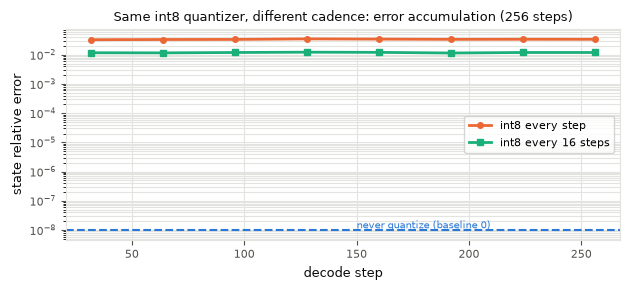

In [6]:
get_ipython().run_line_magic("matplotlib", "inline")
import matplotlib.pyplot as plt
PALETTE = ["#2a78d6", "#eb6834", "#1baf7a"]
ts = list(range(32, T_LONG + 1, 32))
fig, ax = plt.subplots(figsize=(6.4, 3.0))
ax.semilogy(ts, log["every step"], color=PALETTE[1], lw=2, marker="o", ms=4, label="int8 every step")
ax.semilogy(ts, log["every 16"],  color=PALETTE[2], lw=2, marker="s", ms=4, label="int8 every 16 steps")
ax.axhline(1e-8, color=PALETTE[0], lw=1.5, ls="--")
ax.text(150, 1.15e-8, "never quantize (baseline 0)", fontsize=7.5, color=PALETTE[0])
ax.set_xlabel("decode step", fontsize=9, color="#0b0b0b")
ax.set_ylabel("state relative error", fontsize=9, color="#0b0b0b")
ax.set_title("Same int8 quantizer, different cadence: error accumulation (256 steps)", fontsize=9, color="#0b0b0b")
ax.grid(True, which="both", color="#e3e3e0", lw=0.8)
for sp in ax.spines.values(): sp.set_color("#e3e3e0")
ax.tick_params(colors="#52514e", labelsize=8)
ax.legend(fontsize=8)
fig.tight_layout(); plt.show()

## 4. 解读 —— 两个改进方向

- **每步量化** (橙): 误差随步数**持续增长** (~3.3%→3.4% 且趋势向上)。原因: 舍入误差写回
  递推系统, 后续每一步都基于带误差的状态再舍入;
- **每 16 步量化** (青): 误差立刻降一个多量级 —— 注入频率÷16, 两次注入之间误差**不增长**
  (fp32 递推自己不产生误差);
- 但 `every 16` 的平台仍然在 ~0.6-0.7% 量级: 每次注入的**单次 round-trip 误差**还是 per-tensor
  那个 ~1% 水平 (见 §2)。

所以剩下的问题是: **能不能让"每 16 步那一次"更准?** —— 这就是 LeapQuant 量化器干的事 (教程 3)。
另外一个自然问题 "为什么不能干脆不量化?" —— 见教程 1 §4, 显存放不下。

## 小结 (教程 2)

- 对称 int8: 刻度尺 $s=\max|x|/127$, 误差来自 round 舍入, per-tensor 单次 round-trip ~1%;
- 量化节奏比量化器本身更致命: 每步量化 → 误差递归滚雪球; 窗口节奏 → 误差只在边界注入;
- 窗口 + 朴素 int8 已好 ~6×, 但单次误差还是太大。

→ **教程 3**: LeapQuant 量化器 —— 基 + 双尺度 + 补偿, 单次 round-trip 误差 0.458%, 比朴素 int8 好 2.4×。